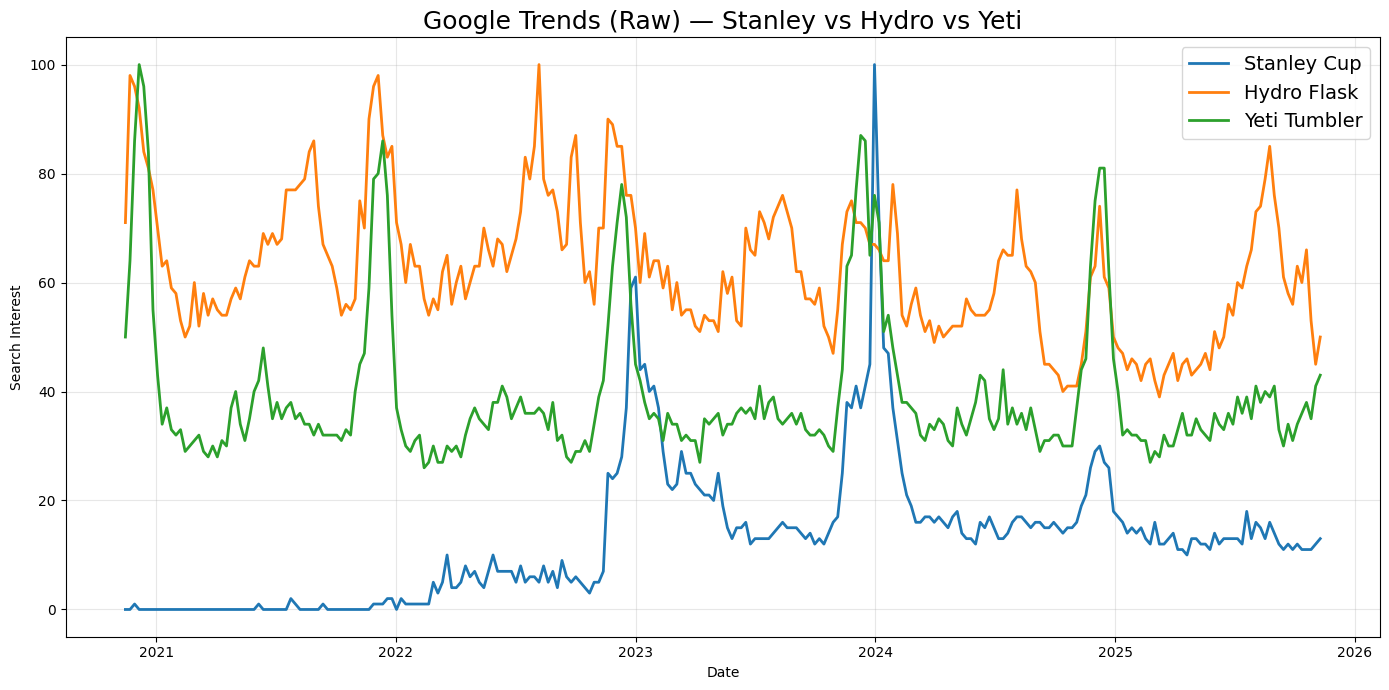

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import re
import requests
from io import StringIO

def load_raw_gt(share_url, colname):
    # Extract ID
    fid = re.search(r"/d/([A-Za-z0-9_-]+)", share_url).group(1)
    url = f"https://drive.google.com/uc?export=download&id={fid}"

    # Download raw CSV
    r = requests.get(url)
    r.raise_for_status()
    csv_text = r.text

    # Google Trends usually has 2 header lines
    try:
        df = pd.read_csv(StringIO(csv_text), skiprows=2)
    except:
        df = pd.read_csv(StringIO(csv_text))

    df = df.iloc[:, 0:2]  # keep first two columns
    df.columns = ["date", colname]
    df["date"] = pd.to_datetime(df["date"])

    return df

# ---- LOAD YOUR 3 FILES ----
stanley = load_raw_gt("https://drive.google.com/file/d/1iiR0anFQ8poXepZTaQSc9QSxC8ZSuZUn/view?usp=sharing", "Stanley")
hydro   = load_raw_gt("https://drive.google.com/file/d/1dWk4pgKNI9dFCw8lJmx5qvPMa6AA_oCU/view?usp=sharing", "HydroFlask")
yeti    = load_raw_gt("https://drive.google.com/file/d/1jZMNFhxR9cL-inyehEZxFi9v9ug8GTxA/view?usp=sharing", "Yeti")

# ---- MERGE WITHOUT CHANGING ANY VALUES ----
merged = stanley.merge(hydro, on="date", how="outer") \
                .merge(yeti, on="date", how="outer") \
                .sort_values("date")

# ---- RAW PLOT (NO EDITS TO DATA) ----
plt.figure(figsize=(14,7))
plt.plot(merged["date"], merged["Stanley"], label="Stanley Cup", linewidth=2)
plt.plot(merged["date"], merged["HydroFlask"], label="Hydro Flask", linewidth=2)
plt.plot(merged["date"], merged["Yeti"], label="Yeti Tumbler", linewidth=2)

plt.title("Raw Google Trends — Stanley vs Hydro vs Yeti", fontsize=18)
plt.xlabel("Date")
plt.ylabel("Search Interest")
plt.legend(fontsize=14)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
